In [1]:
# ============================================
# Customer Churn Prediction - Full Version
# ============================================

# 1) Install and download the dataset from Kaggle
!pip install -q kagglehub

import kagglehub
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from xgboost import XGBClassifier

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
csv_path = os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("File path:", csv_path)

# 2) Load and clean the data
df = pd.read_csv(csv_path)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna().drop(columns=["customerID"])
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print("Rows:", len(df), "| Churn rate: %.1f%%" % (df["Churn"].mean() * 100))

# 3) Encode categorical variables
df = pd.get_dummies(df, drop_first=True)

# 4) Train/test split
X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 5) Train the model
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    eval_metric="logloss",
    random_state=42,
)
model.fit(X_train, y_train)

# 6) Evaluate the model
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred))
print("AUC:", round(roc_auc_score(y_test, proba), 3))

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
File path: /kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
Rows: 7032 | Churn rate: 26.6%
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1033
           1       0.62      0.54      0.58       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.78      1407

AUC: 0.835


 threshold  precision  recall    f1  flagged_customers
      0.20      0.464   0.840 0.598                676
      0.25      0.482   0.797 0.601                618
      0.30      0.506   0.770 0.611                569
      0.35      0.548   0.730 0.626                498
      0.40      0.585   0.671 0.625                429
      0.45      0.583   0.599 0.591                384
      0.50      0.618   0.540 0.576                327
      0.55      0.652   0.465 0.543                267
      0.60      0.689   0.390 0.498                212

Best threshold: 0.37 | Expected profit: 16,500


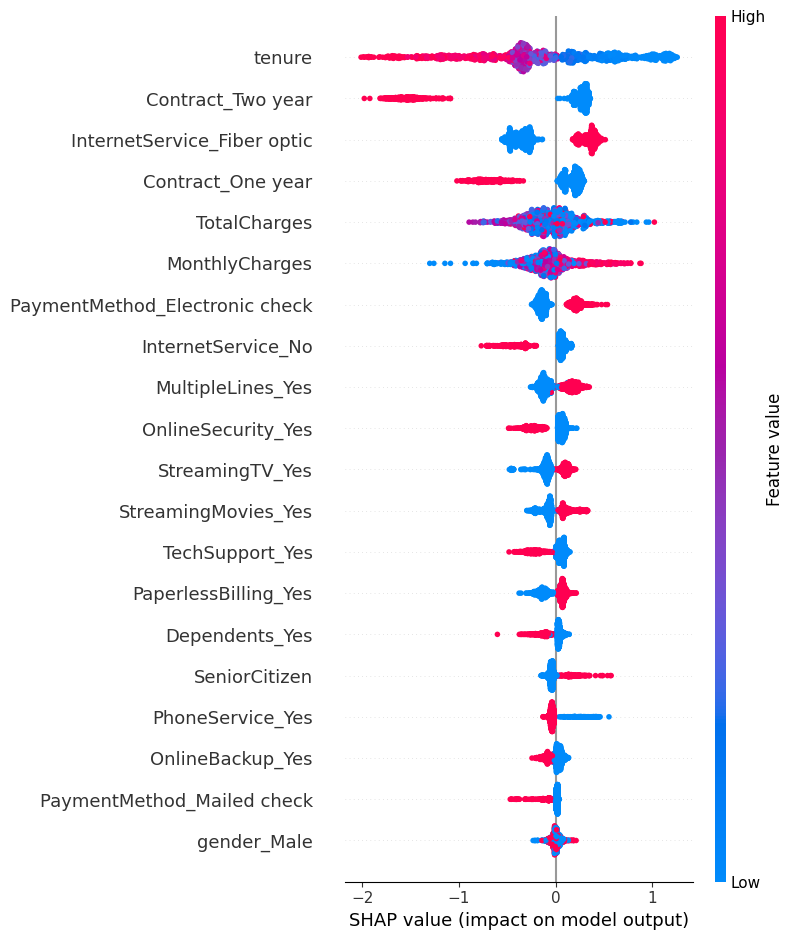

In [2]:
# ============================================
# Threshold Analysis (Business View)
# ============================================
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.65, 0.05)
rows = []
for t in thresholds:
    p = (proba >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_test, p),
        "recall": recall_score(y_test, p),
        "f1": f1_score(y_test, p),
        "flagged_customers": int(p.sum()),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ============================================
# Profit-based optimal threshold
# ============================================
# Assumptions (change these to match your business)
customer_value = 500      # value of retaining one churner
campaign_cost = 50        # cost of contacting one customer
success_rate = 0.30       # % of churners saved by the campaign

best_t, best_profit = None, -np.inf
for t in np.arange(0.05, 0.95, 0.01):
    p = (proba >= t).astype(int)
    tp = ((p == 1) & (y_test == 1)).sum()
    flagged = p.sum()
    profit = tp * success_rate * customer_value - flagged * campaign_cost
    if profit > best_profit:
        best_t, best_profit = t, profit

print(f"\nBest threshold: {best_t:.2f} | Expected profit: {best_profit:,.0f}")

# ============================================
# SHAP: why do customers churn?
# ============================================
!pip install -q shap
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

Streamlit Dashboard

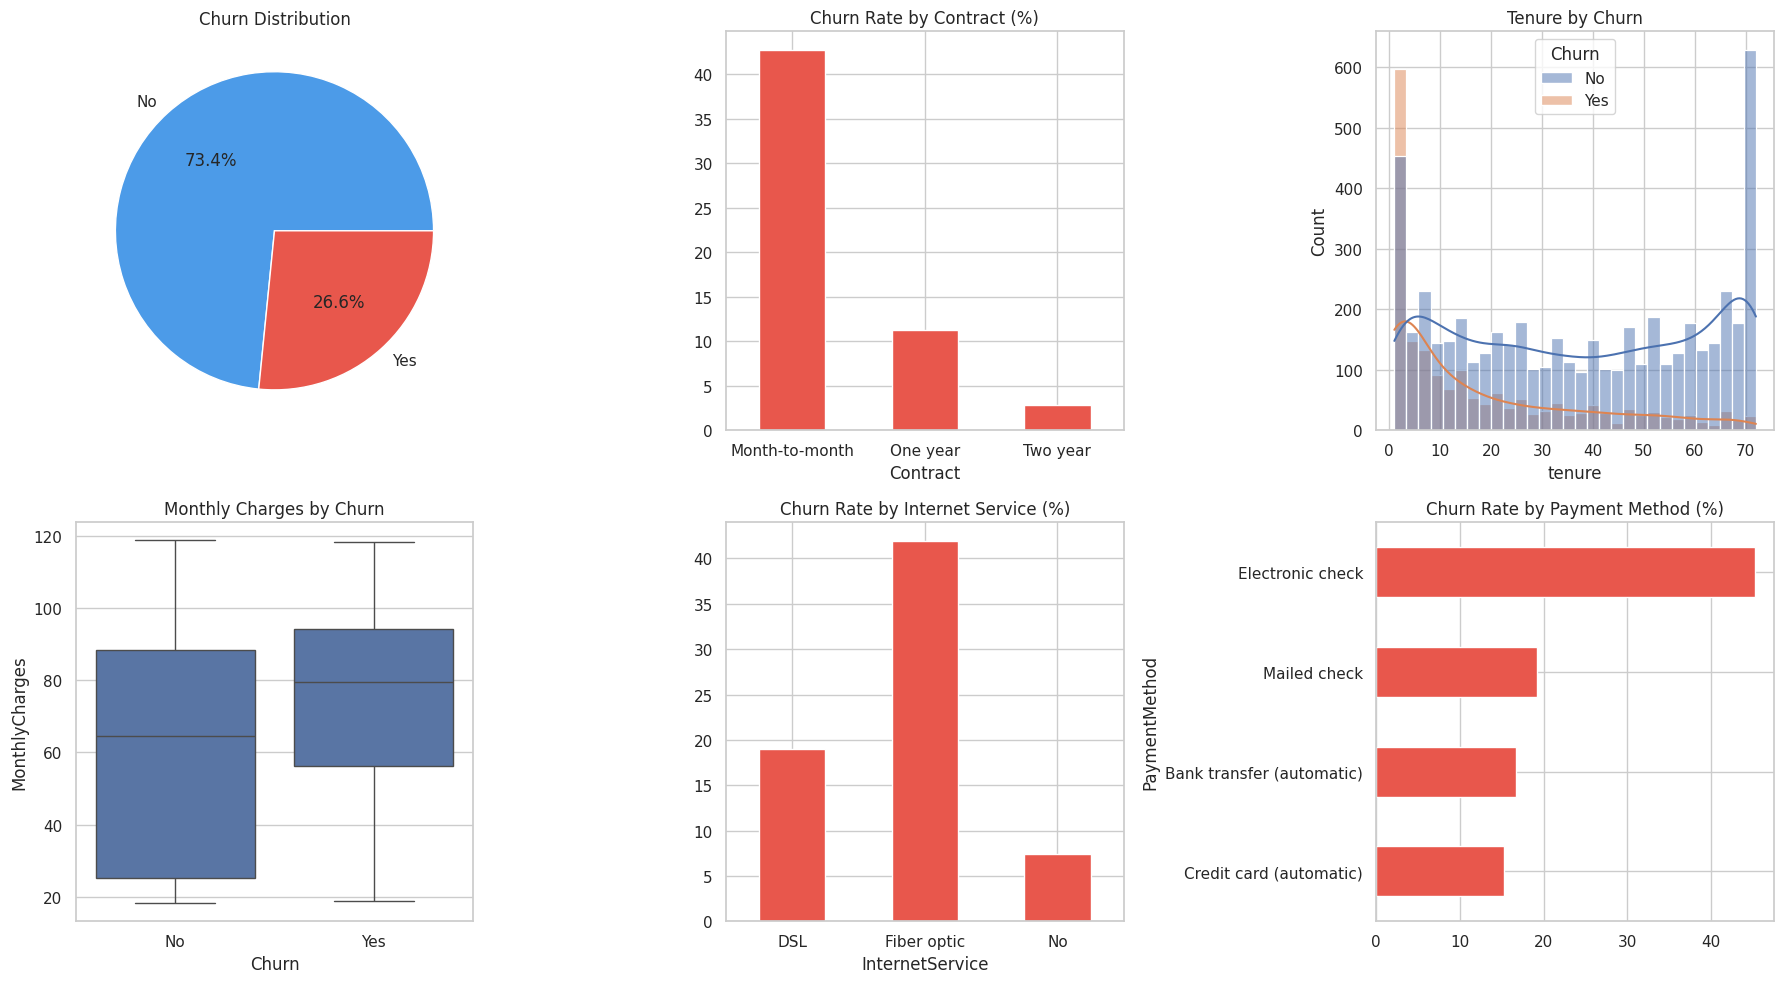

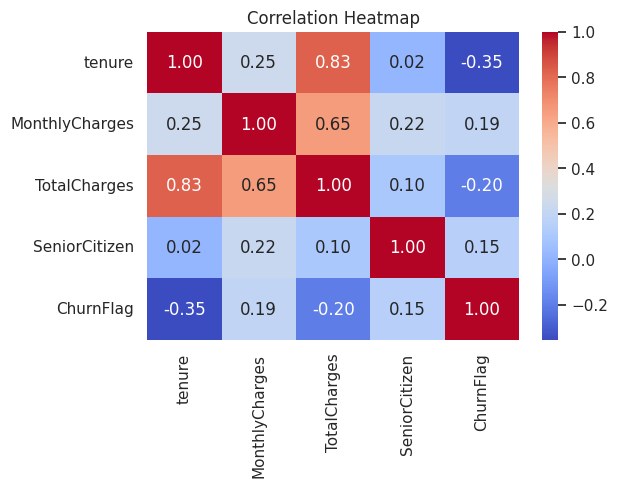

TenureGroup
0-12     47.7
13-24    28.7
25-48    20.4
49-72     9.5
Name: ChurnFlag, dtype: float64


In [3]:
# ============================================
# EDA: Exploratory Data Analysis
# ============================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Reload raw data (df was overwritten by get_dummies)
raw = pd.read_csv(csv_path)
raw["TotalCharges"] = pd.to_numeric(raw["TotalCharges"], errors="coerce")
raw = raw.dropna()
raw["ChurnFlag"] = (raw["Churn"] == "Yes").astype(int)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1) Churn distribution
raw["Churn"].value_counts().plot.pie(
    ax=axes[0, 0], autopct="%1.1f%%", colors=["#4C9BE8", "#E8574C"]
)
axes[0, 0].set_title("Churn Distribution")
axes[0, 0].set_ylabel("")

# 2) Churn rate by contract
(raw.groupby("Contract")["ChurnFlag"].mean() * 100).plot.bar(
    ax=axes[0, 1], color="#E8574C"
)
axes[0, 1].set_title("Churn Rate by Contract (%)")
axes[0, 1].tick_params(axis="x", rotation=0)

# 3) Tenure distribution by churn
sns.histplot(data=raw, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[0, 2])
axes[0, 2].set_title("Tenure by Churn")

# 4) Monthly charges by churn
sns.boxplot(data=raw, x="Churn", y="MonthlyCharges", ax=axes[1, 0])
axes[1, 0].set_title("Monthly Charges by Churn")

# 5) Churn rate by internet service
(raw.groupby("InternetService")["ChurnFlag"].mean() * 100).plot.bar(
    ax=axes[1, 1], color="#E8574C"
)
axes[1, 1].set_title("Churn Rate by Internet Service (%)")
axes[1, 1].tick_params(axis="x", rotation=0)

# 6) Churn rate by payment method
(raw.groupby("PaymentMethod")["ChurnFlag"].mean() * 100).sort_values().plot.barh(
    ax=axes[1, 2], color="#E8574C"
)
axes[1, 2].set_title("Churn Rate by Payment Method (%)")

plt.tight_layout()
plt.show()

# Correlation heatmap (numeric features)
plt.figure(figsize=(6, 4))
sns.heatmap(
    raw[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]].corr(),
    annot=True, cmap="coolwarm", fmt=".2f",
)
plt.title("Correlation Heatmap")
plt.show()

# Churn rate by tenure group
raw["TenureGroup"] = pd.cut(
    raw["tenure"], bins=[0, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
)
print((raw.groupby("TenureGroup", observed=True)["ChurnFlag"].mean() * 100).round(1))

Streamlit

In [4]:
# ============================================
# Save model artifacts and write the Streamlit app
# ============================================
!pip install -q streamlit

import joblib

joblib.dump(
    {
        "model": model,
        "columns": list(X_train.columns),
        "dtypes": X_train.dtypes.astype(str).to_dict(),
    },
    "churn_model.joblib",
)

app_code = '''
import streamlit as st
import pandas as pd
import joblib
import shap

st.set_page_config(page_title="Churn Predictor", layout="wide")

@st.cache_resource
def load():
    art = joblib.load("churn_model.joblib")
    return art["model"], art["columns"], art["dtypes"], shap.TreeExplainer(art["model"])

model, cols, dtypes, explainer = load()

st.title("Customer Churn Predictor")
st.caption("Enter customer details to see churn probability and the main reasons.")

threshold = st.sidebar.slider("Decision threshold", 0.10, 0.90, 0.37, 0.01)
st.sidebar.write("Customers above this probability are flagged as high risk.")

c1, c2, c3 = st.columns(3)
with c1:
    gender = st.selectbox("Gender", ["Female", "Male"])
    senior = st.selectbox("Senior citizen", [0, 1])
    partner = st.selectbox("Partner", ["No", "Yes"])
    dependents = st.selectbox("Dependents", ["No", "Yes"])
    tenure = st.slider("Tenure (months)", 0, 72, 12)
    phone = st.selectbox("Phone service", ["Yes", "No"])
    multi = st.selectbox("Multiple lines", ["No", "Yes", "No phone service"])
with c2:
    internet = st.selectbox("Internet service", ["Fiber optic", "DSL", "No"])
    sec = st.selectbox("Online security", ["No", "Yes", "No internet service"])
    backup = st.selectbox("Online backup", ["No", "Yes", "No internet service"])
    device = st.selectbox("Device protection", ["No", "Yes", "No internet service"])
    tech = st.selectbox("Tech support", ["No", "Yes", "No internet service"])
    tv = st.selectbox("Streaming TV", ["No", "Yes", "No internet service"])
    movies = st.selectbox("Streaming movies", ["No", "Yes", "No internet service"])
with c3:
    contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
    paperless = st.selectbox("Paperless billing", ["Yes", "No"])
    pay = st.selectbox("Payment method", [
        "Electronic check", "Mailed check",
        "Bank transfer (automatic)", "Credit card (automatic)"])
    monthly = st.number_input("Monthly charges", 18.0, 120.0, 70.0)
    total = st.number_input("Total charges", 0.0, 9000.0, float(monthly * max(tenure, 1)))

if st.button("Predict", type="primary"):
    row = pd.DataFrame(0, index=[0], columns=cols, dtype=float)
    row["SeniorCitizen"] = senior
    row["tenure"] = tenure
    row["MonthlyCharges"] = monthly
    row["TotalCharges"] = total

    cats = {
        "gender": gender, "Partner": partner, "Dependents": dependents,
        "PhoneService": phone, "MultipleLines": multi,
        "InternetService": internet, "OnlineSecurity": sec,
        "OnlineBackup": backup, "DeviceProtection": device,
        "TechSupport": tech, "StreamingTV": tv, "StreamingMovies": movies,
        "Contract": contract, "PaperlessBilling": paperless,
        "PaymentMethod": pay,
    }
    for k, v in cats.items():
        name = f"{k}_{v}"
        if name in cols:
            row[name] = 1
    row = row.astype(dtypes)

    prob = float(model.predict_proba(row)[:, 1][0])
    st.metric("Churn probability", f"{prob:.1%}")

    if prob >= threshold:
        st.error("HIGH RISK: recommend a retention action.")
    else:
        st.success("LOW RISK: no action needed.")

    sv = explainer.shap_values(row)[0]
    exp = pd.DataFrame({"feature": cols, "impact": sv})
    exp = exp.reindex(exp["impact"].abs().sort_values(ascending=False).index).head(8)

    st.subheader("Top reasons (SHAP)")
    st.caption("Positive = increases churn risk, negative = decreases it.")
    st.bar_chart(exp.set_index("feature")["impact"])

    if prob >= threshold:
        st.subheader("Suggested actions")
        if contract == "Month-to-month":
            st.write("- Offer a discount to move to a 1 or 2 year contract.")
        if internet == "Fiber optic" and tech == "No":
            st.write("- Offer free or discounted TechSupport and OnlineSecurity.")
        if pay == "Electronic check":
            st.write("- Encourage automatic payment (card or bank transfer).")
        if tenure < 12:
            st.write("- Add an onboarding or loyalty offer for new customers.")
'''
with open("app.py", "w") as f:
    f.write(app_code)
print("app.py and churn_model.joblib saved")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 53.0 MB/s eta 0:00:00
app.py and churn_model.joblib saved


In [5]:
# ============================================
# Run Streamlit in Colab through a public tunnel
# ============================================
!streamlit run app.py --server.port 8501 &>/content/logs.txt &
!sleep 5
print("Your tunnel password (public IP):")
!curl -s ipv4.icanhazip.com
!npx -y localtunnel --port 8501

Your tunnel password (public IP):
136.108.27.213
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙your url is: https://afraid-wombats-send.loca.lt
^C


                     CV AUC  Test AUC  Recall@0.5  Precision@0.5  Recall@0.37  Precision@0.37  F1@0.37
Model                                                                                                 
Logistic Regression   0.846     0.836       0.575          0.648        0.706           0.556    0.622
Random Forest         0.847     0.840       0.476          0.636        0.687           0.572    0.625
XGBoost               0.846     0.835       0.540          0.618        0.714           0.567    0.632


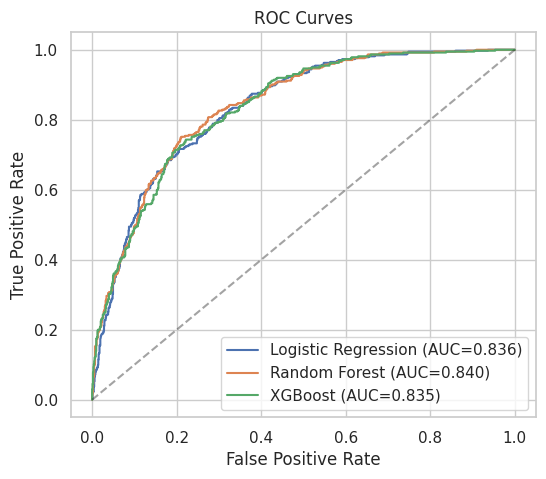

In [8]:
# ============================================
# Part A: Model Comparison
# ============================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=5,
        random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        eval_metric="logloss", random_state=42
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
test_probas = {}

for name, m in models.items():
    cv_auc = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    test_probas[name] = p
    pred_default = (p >= 0.5).astype(int)
    pred_tuned = (p >= 0.37).astype(int)
    results.append({
        "Model": name,
        "CV AUC": cv_auc,
        "Test AUC": roc_auc_score(y_test, p),
        "Recall@0.5": recall_score(y_test, pred_default),
        "Precision@0.5": precision_score(y_test, pred_default),
        "Recall@0.37": recall_score(y_test, pred_tuned),
        "Precision@0.37": precision_score(y_test, pred_tuned),
        "F1@0.37": f1_score(y_test, pred_tuned),
    })

comparison = pd.DataFrame(results).set_index("Model").round(3)
print(comparison.to_string())

plt.figure(figsize=(6, 5))
for name, p in test_probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()


Sensitivity to campaign success rate (value=500, cost=50)
 success_rate  best_threshold  profit
         0.15            0.76    1150
         0.20            0.55    4050
         0.30            0.37   16500
         0.40            0.37   29850
         0.50            0.14   46100

Sensitivity to customer value (cost=50, success=30%)
 customer_value  best_threshold  profit
            300            0.63    2730
            500            0.37   16500
            800            0.14   42720
           1200            0.13   83570

Sensitivity to campaign cost (value=500, success=30%)
 campaign_cost  best_threshold  profit
            20            0.13   35480
            50            0.37   16500
            80            0.63    5160
           120            0.78     750


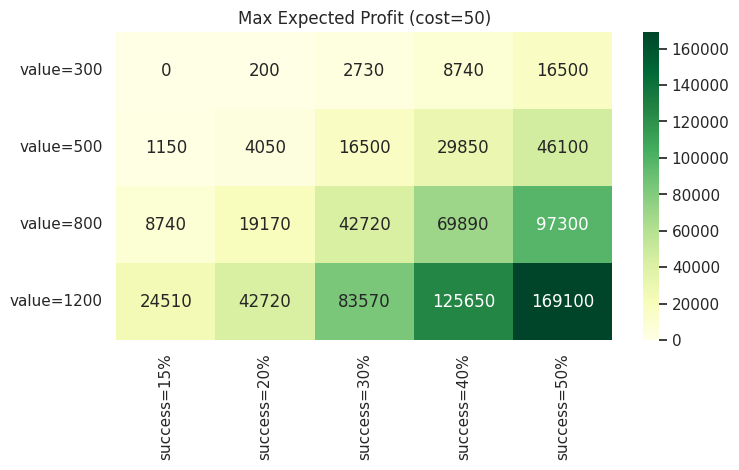

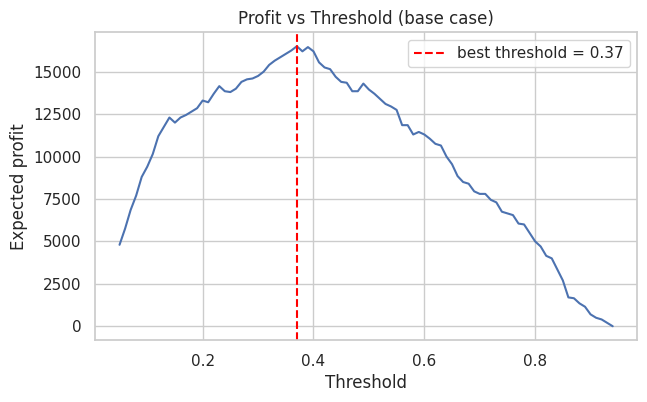

In [9]:
# ============================================
# Part B: Sensitivity Analysis (profit assumptions)
# ============================================
def best_threshold(proba, y_true, value, cost, success):
    best_t, best_profit = None, -np.inf
    y_arr = np.asarray(y_true)
    for t in np.arange(0.05, 0.95, 0.01):
        p = (proba >= t).astype(int)
        tp = ((p == 1) & (y_arr == 1)).sum()
        profit = tp * success * value - p.sum() * cost
        if profit > best_profit:
            best_t, best_profit = t, profit
    return best_t, best_profit

def run_scenarios(title, key, values, args_fn):
    rows = []
    for v in values:
        t, pr = best_threshold(proba, y_test, *args_fn(v))
        rows.append({key: v, "best_threshold": round(t, 2), "profit": round(pr)})
    print("\n" + title)
    print(pd.DataFrame(rows).to_string(index=False))

# 1) Campaign success rate
run_scenarios(
    "Sensitivity to campaign success rate (value=500, cost=50)",
    "success_rate", [0.15, 0.20, 0.30, 0.40, 0.50],
    lambda s: (500, 50, s),
)

# 2) Customer value
run_scenarios(
    "Sensitivity to customer value (cost=50, success=30%)",
    "customer_value", [300, 500, 800, 1200],
    lambda v: (v, 50, 0.30),
)

# 3) Campaign cost
run_scenarios(
    "Sensitivity to campaign cost (value=500, success=30%)",
    "campaign_cost", [20, 50, 80, 120],
    lambda c: (500, c, 0.30),
)

# 4) Heatmap: success rate x customer value
succ = [0.15, 0.20, 0.30, 0.40, 0.50]
vals = [300, 500, 800, 1200]
grid = pd.DataFrame(
    [[best_threshold(proba, y_test, v, 50, s)[1] for s in succ] for v in vals],
    index=[f"value={v}" for v in vals],
    columns=[f"success={int(s * 100)}%" for s in succ],
)
plt.figure(figsize=(8, 4))
sns.heatmap(grid, annot=True, fmt=".0f", cmap="YlGn")
plt.title("Max Expected Profit (cost=50)")
plt.show()

# 5) Profit curve for the base case
ts = np.arange(0.05, 0.95, 0.01)
y_arr = np.asarray(y_test)
profits = []
for t in ts:
    p = (proba >= t).astype(int)
    tp = ((p == 1) & (y_arr == 1)).sum()
    profits.append(tp * 0.30 * 500 - p.sum() * 50)

plt.figure(figsize=(7, 4))
plt.plot(ts, profits)
plt.axvline(0.37, color="red", linestyle="--", label="best threshold = 0.37")
plt.xlabel("Threshold")
plt.ylabel("Expected profit")
plt.title("Profit vs Threshold (base case)")
plt.legend()
plt.show()